# <center> ISEL - AA </center>
## <center>Semestre 2024/25 </center>
###  <center> Trabalho Prático Nº2 </center>
###  <center> Classificação de Críticas de Cinema do IMDb </center>

Trabalho realizado por:
* João Ramos, numero <b> 50730 </b>
* Fábio Pestana, numero <b> 50756 </b>


<b> Turma: 51D </b> <br></br>
<b> Docente: Gonçalo Marques </b>

##  Introdução 

Este trabalho propõe uma abordagem sistemática para explorar e modelar um conjunto de dados fornecidos pela *Internet Movie Database* (IMDb), que contém 50000 críticas de filmes, associadas a pontuações numa escala de 1 a 10. As críticas neutras, correspondentes às pontuações 5 e 6, foram previamente excluídas, de forma a facilitar a análise e construção de modelos preditivos.

O objetivo principal deste trabalho é desenvolver soluções para resolver três tarefas fundamentais: classificação, regressão e *clustering* de críticas de cinema. Estas tarefas visam compreender os padrões nos textos e prever ou agrupar as críticas com base no seu conteúdo e pontuações associadas. O trabalho enfatiza a importância de pré-processamento eficiente e de seleção de modelos adequados.

Para alcançar esses objetivos, o vocabulário será construído utilizando a técnica TF-IDF (*Term Frequency-Inverse Document Frequency*), permitindo uma representação vetorial dos textos que preserve informações semânticas relevantes. A mesma base de vocabulário será utilizada tanto nas tarefas supervisionadas (classificação e regressão) quanto nas não supervisionadas (*clustering*).

Na tarefa de classificação multi-classe, serão desenvolvidos modelos para prever diretamente a pontuação de uma crítica entre as classes {1, 2, 3, 4, 7, 8, 9, 10}. Na tarefa de regressão, os modelos preditivos estimarão uma pontuação contínua, que será posteriormente convertida em classes discretas, permitindo a comparação direta com os resultados da classificação. Por fim, na tarefa de *clustering*, serão aplicados métodos não supervisionados para agrupar as críticas de acordo com tópicos subjacentes.

Dada a dimensão dos dados, algumas restrições metodológicas foram impostas, técnicas como validação cruzada ``k-fold`` e ``GridSearchCV`` não serão utilizadas devido ao elevado custo computacional. Além disso, opta-se por não remover as *stopwords*, uma vez que estas podem conter informações contextuais importantes para a análise das críticas.

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pickle
import re

from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.svm import LinearSVC

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay, r2_score, mean_squared_error

from sklearn.feature_extraction.text import TfidfVectorizer
from nltk.stem import SnowballStemmer

from sklearn.decomposition import TruncatedSVD
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from sklearn.cluster import KMeans

## Leitura dos dados e chaves do *dataset*

In [2]:
fileDir = ''
fName='imdbFull.p'

D=pickle.load(open(fileDir + fName,'rb'))

print(D.keys())

dict_keys(['data', 'target', 'DESCR'])


## Dados e classes do *dataset*

In [3]:
X = D['data']
y = D['target']

print('Data:', len(X))
print('Shape do target:', y.shape)

print('Classes do dataset:', np.unique(y)) 

Data: 50000
Shape do target: (50000,)
Classes do dataset: [ 1  2  3  4  7  8  9 10]


## Visualização do número de críticas por nota

Como etapa inicial do trabalho, realizou-se uma análise dos dados com o objetivo de visualizar a distribuição das notas atribuídas às críticas de cinema no conjunto de dados fornecido. Para isso, foi gerado um histograma que apresenta o número de críticas associadas a cada nota no intervalo de 1 a 10.

Para tal, fez se uma contagem das notas utilizando a função ``np.bincount`` para calcular a frequência de cada nota no intervalo de 1 a 10. A opção ``minlength = 11`` foi utilizada para garantir que todas as notas entre 1 e 10 fossem consideradas, mesmo que algumas delas não estivessem presentes no conjunto de dados.

O objetivo deste passo foi avaliar a presença de desequilíbrios no número de críticas por nota, algo que pode impactar significativamente o desempenho dos modelos supervisionados. Caso uma ou mais classes apresentem um número muito reduzido de amostras, será necessário considerar técnicas de balanceamento ou ajustes nos modelos para lidar com esse desbalanço.

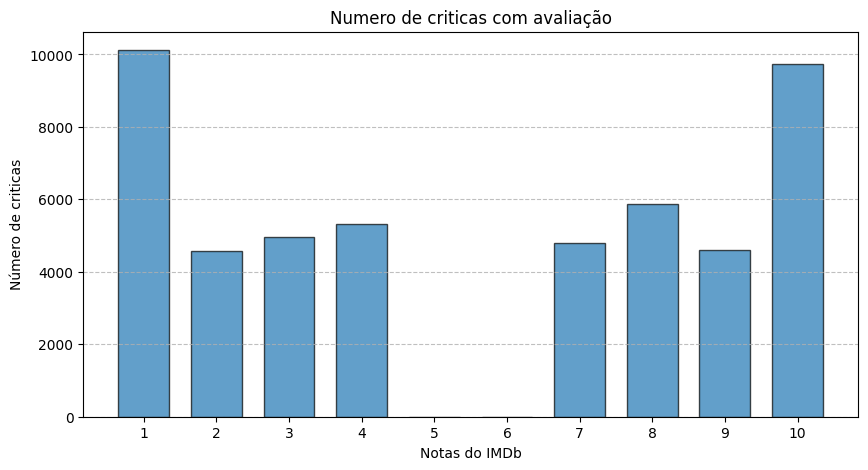

In [4]:
def plot_histogram(data, title, xlabel, ylabel):
    """
    Método que gera um histograma com barras que representam a frequência de avaliações em uma 
    escala de 1 a 10. 
    A função também adiciona uma grade no eixo y para melhorar a visualização das frequências das 
    avaliações.

    Args:
        - data - Dados a serem analisados, representando as avaliações (notas) das críticas de filmes.
        - title - Título do gráfico, que será exibido no topo da figura.
        - xlabel -  Rótulo do eixo x, representando o que está sendo medido no eixo horizontal.
        - ylabel - Rótulo do eixo y, representando o que está sendo medido no eixo vertical.
    """
    plt.figure(figsize=(10, 5))
    
    # Contar a frequência de cada valor único no intervalo de 1 a 10
    counts = np.bincount(data, minlength=11)[1:11] 
    values = np.arange(1, 11)
    
    plt.bar(values, counts, width=0.7, edgecolor='black', alpha=0.7)
    
    plt.xticks(values)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid(axis='y', linestyle='--', alpha=0.8)
    plt.show()

plot_histogram(y, "Numero de criticas com avaliação", "Notas do IMDb", "Número de criticas")

## Separação do *dataset* para o treino e teste dos modelos

Nesta etapa, o *dataset* foi dividido em três conjuntos principais: treino, validação e teste. Esta separação é essencial para garantir que o modelo seja treinado e avaliado de forma robusta, maximizando a sua capacidade de generalização em dados nunca vistos. A divisão segue as seguintes proporções:

 * Conjunto de Treino (``Xt_hiperparametros``): Este conjunto é utilizado para treinar o modelo, segundo combinações de hiperparâmetros. Através deste conjunto, o modelo aprende os padrões dos dados. A divisão de 60% dos dados para treino permite que o modelo tenha informações suficientes para aprender;

 * Conjunto de Validação (``Xv``): Após o treino, este conjunto é utilizado para avaliar o desempenho do modelo com uma combinação dos hiperparâmetros, para assim escolher-se qual a melhor combinação destes para melhorar o desempenho do modelo.
 A validação é importante porque permite que o modelo seja ajustado sem que se utilize o conjunto de teste, evitando que ele "aprenda" esses dados (evitando *overfitting*), o que prejudicaria a avaliação. A divisão de 20% para validação oferece dados suficientes para fazer ajustes ao modelo;

 * Conjunto de Teste (``Xf``): Este conjunto é utilizado para avaliar o desempenho final do modelo em dados nunca vistos, simulando assim a situação real, onde o modelo precisa fazer previsões sobre novos dados. A divisão de 20% permite que o modelo seja testado com dados suficientes para termos uma avaliação mais realista do modelo.

Em código, inicialmente são inicializadas duas variáveis: 
* ``percentagem_treino`` que indica a percentagem do *dataset* que será usada para o conjunto de treino (60%); 

* ``percentagem_validacao`` que indica a percentagem do *dataset* que será usada para o conjunto de validação (20%). 

De seguida, define-se o tamanho de cada conjunto (``treino`` e ``validacao``), teste como será composto pelos restantes 20% do *dataset* não é necessário calcular o seu tamanho. 

Utilizando a indexação, separa-se o conjunto de dados (``X``) e sua classificação (``y``) nos três conjuntos mencionados anteriormente (conjuntos de dados: ``Xt_hiperparametros``, ``Xv``, ``Xf`` e  conjuntos das classes: ``yt_hiperparametros``, ``yv``, ``yf``).

In [5]:
# Percentagens para cada conjunto de dados
# 80% dos dados para o conjunto de treino e resto 20% para o conjunto de testes
percentagem_treino = 0.6
percentagem_validacao = 0.2

tamanho_data = len(X)

treino = int(tamanho_data * percentagem_treino)
validacao = treino + int(tamanho_data * percentagem_validacao)

Xt_hiperparametros = X[:treino] 
yt_hiperparametros = y[:treino]

Xv = X[treino:validacao]
yv = y[treino:validacao]

Xf = X[validacao:]
yf = y[validacao:]

print(f'Data de treino:{len(Xt_hiperparametros)}. Target de treino:{yt_hiperparametros.shape}')
print(f'Data de validacao:{len(Xv)}. Target de teste:{yv.shape}')
print(f'Data de teste:{len(Xf)}. Target de teste:{yf.shape}')

Data de treino:30000. Target de treino:(30000,)
Data de validacao:10000. Target de teste:(10000,)
Data de teste:10000. Target de teste:(10000,)


## Limpeza dos textos

Nesta etapa, fez-se uma limpeza dos textos de cada conjunto de dados, onde aplicou-se transformações nos dados para remover elementos indesejados, uniformizar o texto e garantir uma melhor representação das informações relevantes. 
Para realizar esta etapa, implementou-se a função ``clean_text``, com os seguintes passos:

* Remoção de quebras de linha HTML: Como os textos no *dataset*, tinham o marcador ``<br />`` (utilizado em HTML para indicar quebras de linha), decidiu-se removê-lo apartir do método ``replace`` das strings, este foi substituido por um espaço simples.

* Remoção de carateres não alfabéticos: Fez-se uma limpeza no *dataset* utilizando o módulo ``re`` (expressões regulares), para assim remover números, simbolos de pontuação e outros caracteres que não contribuem para a análise dos dados (estes foram substituídos por espaços), deixando apenas letras (a-z, A-Z) ou caracteres acentuados (\u00C0-\u00FF).

A limpeza dos textos tem um impacto significativo no desempenho dos modelos. Ao remover ruídos, como caracteres não alfabéticos ou marcadores HTML, conseguimos reduzir a complexidade do vocabulário. Este passo é especialmente importante para técnicas como TF-IDF, que dependem de uma representação precisa e consistente do conteúdo textual.

In [6]:
def clean_text (X):
    """
    Método que realiza uma limpeza no texto, removendo tags HTML (quebras de linha) e 
    caracteres não alfabéticos.

    Args:
        - X - Lista de textos a serem limpos.

    Returns:
        - Xfinal - Lista de textos após o processo de limpeza.
    """
    
    Xfinal = [x.replace('<br />', ' ') for x in X]
    Xfinal = [re.sub(r'[^a-zA-Z\u00C0-\u00FF]+', ' ', x) for x in Xfinal]
    return Xfinal

Xt_hiperparametros = clean_text(Xt_hiperparametros)
Xv = clean_text(Xv)
Xf = clean_text(Xf)

## *Stemming*

O *stemming* é uma técnica de processamento de texto utilizada para reduzir palavras às suas raízes ou formas básicas, ou seja, reduzir várias palavras para apenas uma para assim generalizar o texto e facilitar a identificação de palavras chaves no *dataset* para identificar a nota da crítica (exemplo de *stemming*: “Create”,“creative”, “creativity”, “creator” e “creating” passam para o stem “creat”). 

Para esta tarefa, foi utilizado o algoritmo ``SnowballStemmer`` configurado para o idioma inglês. A escolha do ``SnowballStemmer`` em relação a outros deve-se aos seguintes fatores:

* ``SnowballStemmer``: é uma versão melhorada do ``PorterStemmer``, oferece melhor desempenho. Produz *stems* mais consistentes e relevantes para o idioma inglês, e é menos agressivo que o ``LancasterStemmer``.

* ``LancasterStemmer``: é um algoritmo de *stemming* mais agressivo o que pode levar a perdas de significado que prejudiquem a análise.

* ``PorterStemmer``: é uma versão mais antiga e menos eficiente que o ``SnowballStemmer``.

No código, cada palavra nos textos foi processada através do método ``stem`` do ``SnowballStemmer``, garantindo que apenas a forma reduzida (*stem*) fosse mantida.

## Representação TF-IDF

Após o *stemming*, os textos foram transformados em uma representação vetorial utilizando o ``TfidfVectorizer``. Essa técnica combina a frequência dos termos com a inversa da frequência em todos os documentos, resultando em uma representação que destaca palavras mais importantes e menos comuns. Os parâmetros escolhidos foram:

* ``min_df=3``: Especifica que um termo deve aparecer em pelo menos três documentos para ser incluído no vocabulário. Isso ajuda a eliminar termos muito raros, que não contribuem significativamente para a análise.

* ``max_features``: Define o número máximo de *features* (termos) a serem considerados no vocabulário. Neste caso, foi configurado como o número de amostras de treino menos 1.000 ( ``len(Xt_hiperparametros) - 1000 ``). Esta escolha foi feita para equilibrar a representatividade dos termos e o custo computacional, especialmente considerando o tamanho do *dataset*.

* ``token_pattern=r'\b\w\w+\b'``: Define o padrão de tokenização. O padrão ``\b\w\w+\b`` inclui palavras com duas ou mais letras. Isso elimina *tokens* muito curtos, como "a" ou "i", que não contribuem para a análise.

* ``ngram_range=(1, 2)``: Considera unigramas (palavras únicas) e bigramas (pares de palavras consecutivas). Essa escolha permite capturar informações contextuais importantes que podem ser ignoradas ao utilizar apenas unigramas.

Neste processo, optou-se por não remover *stopwords* (palavras como "not", "is", "but", etc), pois em críticas de cinema estas palavras desempenham um papel crucial em expressar nuances que diferenciam avaliações de pontuações distintas, como por exemplo:

* "The movie was good" (considerada uma crítica positiva).
* "The movie was <u>not</u> good" (considerada uma crítica negativa).

In [7]:
stemFunc =  SnowballStemmer(language='english')

# Aplica o stemming em cada palavra das críticas de treino
Xt_hiperparametros = [' '.join([stemFunc.stem(w) for w in x.split()]) for x in Xt_hiperparametros]

# Calcula o número máximo de características que serão extraídas
max_feature = len(Xt_hiperparametros) - 1000

tp = r'\b\w\w+\b' # apenas palavras de 2 ou mais caracteres

tfidf = TfidfVectorizer(min_df=3, max_features=max_feature, token_pattern=tp, ngram_range=(1, 2)).fit(Xt_hiperparametros)
Xt_hiperparametros = tfidf.transform(Xt_hiperparametros)
print(Xt_hiperparametros.shape, type(Xt_hiperparametros))

Xv = [' '.join([stemFunc.stem(w) for w in x.split()]) for x in Xv]
Xv = tfidf.transform(Xv)
print(Xv.shape, type(Xv))

(30000, 29000) <class 'scipy.sparse._csr.csr_matrix'>
(10000, 29000) <class 'scipy.sparse._csr.csr_matrix'>


## Classificadores e escolha dos seus hiperparâmetros

Para o problema deste projeto, o grupo escolheu os seguintes classificadores:

* **Logistic Regression** - optou-se por este modelo devido à sua simplicidade e eficácia em problemas de classificação multi-classe. Onde a partir das variáveis que recebe no *dataset*, ele cria limiares de decisão que divide o espaço de amostras de forma a conseguir maximizar a separação entre as classes, com isto consegue indicar a nota de uma crítica;

* **Linear Support Vector Classification** - foi escolhido devido à sua eficácia em problemas de classificação. Ele é baseado na ideia de maximizar a margem de separação entre as classes, o que permite um modelo robusto. O ``LinearSVC`` é um classificador linear como a regressão logística, mas, ao contrário da regressão logística, ele tenta encontrar um hiperplano de separação de maneira otimizada, usando a margem máxima, o que pode melhorar o desempenho caso aja uma boa separação entre as classes. Também foi escolhido pois lida bem com as classes desequilibradas, devido ao parâmetro ``class_weight='balanced'``, que ajusta a penalização de forma que classes com menos amostras recebam maior peso na classificação.

Ao longo do projeto outros classificadores foram testados, no entanto optou-se pelos classificadores referidos anteriormente, pois apresentaram os melhores resultados. Os classificadores testados que não estão apresentados neste trabalho foram os seguintes:

* **RandomForest** - é um classificador baseado em um conjunto de árvores de decisão. Embora o RandomForest seja um modelo flexível, ele não teve um desempenho melhor neste caso específico, possivelmente devido à presença de variáveis irrelevantes.

* **MultinomialDB** - normalmente é eficaz em problemas de classificação de texto. No entanto, neste projeto, as classes estavam desequilibradas (com mais exemplos nas criticas com notas 1 e 10), o que afetou negativamente o desempenho do ``MultinomialNB``. Esse classificador assume que as características são independentes entre si, sendo esta uma das possiveis razões de não ter bons resultados neste *dataset*, pois as críticas de cinema podem ter padrões de dependência significativos entre palavras (por exemplo, expressões como "muito bom" ou "não gostei").

Outros classificadores, como o **KNeighborsClassifier**, não foram considerados devido às suas limitações. O KNN realiza classificação com base no cálculo de distâncias entre os dados durante a fase de classificação (*lazy training*). Com o alto número de dimensões dos dados TF-IDF gerados neste projeto, o KNN foi considerado inadequado para este tipo de dados.

Cada classificardor foi ajustado através da busca pelos melhores hiperparâmetros, para assim estes terem um melhor desempenho a classificar as criticas. Este processo foi realizado com base no conjunto de treino e avaliado com o conjunto de validação.

## Logistic Regression

A Logistic Regression é um modelo linear simples que é eficiente para tarefas de classificação multi-classe. Ele estima a probabilidade de uma amostra pertencer a uma classe específica utilizando uma combinação linear das variáveis de entrada, sendo esta probabilidade mapeada por uma função logística. 

No caso de problemas de classificação multi-classe, a Logistic Regression utiliza a abordagem *one-vs-rest*, onde uma função de regressão logística é treinada para cada classe, separadamente, usando todas as outras classes como fundo.

Neste projeto, a Logistic Regression foi escolhida pela sua simplicidade e eficiência, especialmente em problemas onde as classes podem ser separadas de forma linear.

#### Hiperparâmetros ajustados:

Para otimizar o desempenho deste modelo, ajustamos os seguintes hiperparâmetros:

 * **Parâmetro de regularização (C):** O valor de ``C`` afeta diretamente a capacidade do modelo de se ajustar aos dados de treino, ou seja, controla como o modelo é regulado.<br>
 Um valor alto de ``C`` reduz a regularização, permitindo ao modelo ajustar-se mais aos dados de treino, o que pode levar ao *overfitting* se os dados de treino não forem suficientemente representativos.
 Um valor baixo de ``C`` aumenta a regularização, simplificando o modelo e aumentando sua capacidade de generalização, mas com maior tolerância a erros.
 A escolha dos valores de ``C`` foi baseada na tentativa de encontrar um equilíbrio entre a capacidade de generalização do modelo e a precisão na previsão das classes de crítica.

    Valores testados: 0.1 a 1.0, com incrementos de 0.1. <br><br>

Os restantes parâmetros do modelo foram os seguintes:
 * **Tol (Tolerância para Convergência):** A ``tol`` define o critério de convergência do algoritmo de otimização. Ele é utilizado para determinar quando o processo de otimização pode ser interrompido, ou seja, a convergência é alcançada quando as atualizações nos coeficientes do modelo são menores que o valor definido para ``tol``. Um valor muito pequeno de ``tol`` pode levar a uma convergência mais lenta, enquanto um valor maior pode resultar em uma convergência prematura.

    Valores utilizado: 1e-3

 * **Class Weight:** O parâmetro ``class_weight='balanced'`` foi utilizado para ajustar o peso das classes, o que é útil em casos onde as classes estão desequilibradas. O uso de ``class_weight='balanced'`` garante que as classes menos representadas tenham um peso maior no cálculo da função de custo, ajudando o modelo a ser mais sensível a essas classes minoritárias.

 * **Max Iter (Número Máximo de Iterações):** O ``max_iter`` define o número máximo de iterações que o solver pode realizar para otimizar os coeficientes.

    Valor utilizado: 1000.

In [8]:
C_options = np.arange(0.1, 1.1, 0.1)

def lr_hiperparametros(Cs, Xt, yt, Xv, yv):
    """
    Método que realiza a busca pelos melhores hiperparâmetros para o modelo Logistic Regression.

    Args:
        - Cs - Lista dos valores a testar para o parâmetro de regularização.
        - Xt - Conjunto de dados de treino.
        - yt - Classificações do conjunto de treino.
        - Xv - Conjunto de dados de validação.
        - yv - Classificações do conjunto de validação.

    Returns:
        - best_params_lg - Melhor combinação de hiperparâmetros encontrada.
        - best_score_lg - Melhor score obtido para o conjunto de validação.
    """
    best_score_lg = 0
    best_params_lg = 0

    for C in Cs:
        lr = LogisticRegression(max_iter=1000, C=C, tol=1e-3, class_weight='balanced')
        lr.fit(Xt, yt)
            
        score = lr.score(Xv, yv)
                        
        if score > best_score_lg:
            best_score_lg = score
            best_params_lg = C

    return best_params_lg, best_score_lg
        
best_params_lg, best_score_lg = lr_hiperparametros(C_options, Xt_hiperparametros, yt_hiperparametros, Xv, yv)

print("Melhores hiperparâmetros para Logistic Regression com base no score:", best_params_lg)
print("Score correspondente:", round(best_score_lg, 3))

Melhores hiperparâmetros para Logistic Regression com base no score: 0.7000000000000001
Score correspondente: 0.404


## Linear Support Vector Classification

O Linear Support Vector Classification (``LinearSVC``) é um classificador baseado em uma versão do Support Vector Machine (SVM), que busca encontrar o melhor hiperplano para separar as diferentes classes no espaço de características. No caso de dados lineares, o ``LinearSVC`` tenta maximizar a margem entre as classes, garantindo que os pontos de dados de diferentes classes fiquem o mais distante possível desse hiperplano, o que ajuda a garantir boa generalização do modelo.

No contexto deste projeto, o ``LinearSVC`` foi escolhido devido à sua robustez e eficiência em problemas de classificação com um grande número de características, como *dataset* do projeto, e à sua capacidade de lidar com classes desequilibradas. O modelo foi configurado para encontrar um equilíbrio entre a precisão e a capacidade de generalização.

#### Hiperparâmetros ajustados:

Para otimizar o desempenho deste modelo, ajustamos os seguintes hiperparâmetros:

 * **Parâmetro de regularização (C):** O valor de ``C`` controla o equilíbrio entre maximizar a margem e minimizar os erros de classificação. Valores altos de ``C`` fazem o modelo tentar classificar todos os dados corretamente, o que pode levar a um modelo muito complexo e sujeito a *overfitting*. Já valores baixos de ``C`` resultam em um modelo mais simples e com maior capacidade de generalização, embora possa ocorrer uma maior margem de erro nas classificações.

   Valores testados: 0.1 a 1.0, com incrementos de 0.1.<br><br>

Os restantes parâmetros do modelo foram os seguintes:

 * **Class Weight:** O parâmetro ``class_weight='balanced'`` foi utilizado para ajustar os pesos das classes. Em problemas com classes desbalanceadas, este parâmetro ajusta a função de custo de forma que as classes minoritárias recebam maior peso, permitindo que o modelo aprenda melhor a classificar essas classes menos representadas.

 * **Max Iter (Número Máximo de Iterações):** O ``max_iter`` determina o número máximo de iterações que o algoritmo pode realizar durante o processo de otimização.
 
   Valor utilizado: 1000.

In [9]:
C_options = np.arange(0.1, 1.1, 0.1)

def linearSVC_hiperparametros(Cs, Xt, yt, Xv, yv):
    """
    Método que realiza a busca pelos melhores hiperparâmetros para o modelo Linear Support Vector Classification.

    Args:
        - Cs - Lista dos valores a testar para o parâmetro de regularização.
        - Xt - Conjunto de dados de treino.
        - yt - Classificações do conjunto de treino.
        - Xv - Conjunto de dados de validação.
        - yv - Classificações do conjunto de validação.

    Returns:
        - best_params_svm - Melhor combinação de hiperparâmetros encontrada.
        - best_score_svm - Melhor score obtido para o conjunto de validação.
    """
    best_score_svm = 0
    best_score_svm = 0 

    for C in Cs:
        svm = LinearSVC(C=C, class_weight='balanced', max_iter=1000)
        svm.fit(Xt, yt)
            
        score = svm.score(Xv, yv)
                        
        if score > best_score_svm:
            best_score_svm = score
            best_params_svm = C

    return best_params_svm, best_score_svm
        
best_params_svm, best_score_svm = linearSVC_hiperparametros(C_options, Xt_hiperparametros, yt_hiperparametros, Xv, yv)

print("Melhores hiperparâmetros para LinearSVC com base no score:", best_params_svm)
print("Score correspondente:", round(best_score_svm, 3))

Melhores hiperparâmetros para LinearSVC com base no score: 0.1
Score correspondente: 0.429


## Conjunto de treino e teste finais

Após a divisão inicial do conjunto de dados em treino, validação e teste, junta-se o conjunto de treino com o da validação, pois o objetivo de conjunto de validação já foi cumprido (servir como conjunto de teste para se descobrir os hiperparâmetros), logo este pode-se juntar com o conjunto de treino para assim os classificadores serem treinados com a maior quantidade possível de dados (80% do *dataset* original).

Como se alterou os conjuntos anteriores, decidiu-se repetir os passos de limpeza de texto e *stemming*. 
A vetorização foi feita novamente tanto para o novo conjunto de treino, quanto para o conjunto de teste, utilizando o modelo ajustado do ``TfidfVectorizer`` (parametros iguais ao anterior com alteração do valor do ``max_features`` para o ``len(Xt) - 1000``). Isso garante que a transformação seja consistente e que o modelo testado no conjunto de teste utilize as mesmas características extraídas do conjunto de treino.

In [10]:
percentagem_treino = percentagem_treino + percentagem_validacao
treino = int(tamanho_data * percentagem_treino)
Xt = X[:treino]
yt = y[:treino]

Xt = clean_text(Xt)
Xt = [' '.join([stemFunc.stem(w) for w in x.split()]) for x in Xt]

max_feature = len(Xt) - 1000

tfidf = TfidfVectorizer(min_df=3, max_features=max_feature, token_pattern=tp, ngram_range=(1, 2)).fit(Xt)
Xt = tfidf.transform(Xt)

Xf = [' '.join([stemFunc.stem(w) for w in x.split()]) for x in Xf]
Xf = tfidf.transform(Xf)
print(Xf.shape, type(Xf))

(10000, 39000) <class 'scipy.sparse._csr.csr_matrix'>


## Avaliação dos Modelos: Logistic Regression e Linear Support Vector Classification

Após a definição dos melhores hiperparâmetros para os dois classificadores, Logistic Regression e Linear Support Vector Classification (``LinearSVC``), os modelos foram treinados utilizando o conjunto de treino (composto pela junção do conjunto de treino e validação) e avaliados utilizando o conjunto de teste. O objetivo desta etapa é verificar a eficácia dos modelos na classificação das críticas de cinema com base nas pontuações.

A comparação destes será feita mais embaixo em conjunto com o regressor.

In [11]:
lr = LogisticRegression(max_iter=1000,
                        C=best_params_lg, 
                        tol=1e-3,
                        class_weight='balanced')

lr.fit(Xt, yt)
print("LogisticRegression treino score:",lr.score(Xt, yt))
print("LogisticRegression teste score:",lr.score(Xf, yf))

y_pred_lr = lr.predict(Xf)
cm_lr = confusion_matrix(yf, y_pred_lr)
lr_report = classification_report(yf, y_pred_lr)

lsvc = LinearSVC(C=best_params_svm, 
                 class_weight='balanced', 
                 max_iter=1000)

lsvc.fit(Xt, yt)
print("LinearSVC treino score:", lsvc.score(Xt, yt))
print("LinearSVC teste score:", lsvc.score(Xf, yf))

y_pred_svm = lsvc.predict(Xf)
cm_svm = confusion_matrix(yf, y_pred_svm)
lsvc_report = classification_report(yf, y_pred_svm)

LogisticRegression treino score: 0.705325
LogisticRegression teste score: 0.41
LinearSVC treino score: 0.78815
LinearSVC teste score: 0.438


## Regressores

Para o problema deste projeto, o grupo escolheu utilizar o regressor **Ridge**. Optou-se por este regressor pela sua capacidade de evitar *overfitting*, especialmente em conjuntos de dados com muitas características. Além disso, a regularização L2 do Ridge ajuda a garantir que os coeficientes do modelo não se tornem excessivamente grandes, o que pode prejudicar a generalização. A escolha do Ridge foi particularmente relevante devido ao grande número de características no conjunto de dados (após a transformação com o ``TfidfVectorizer``) e à necessidade de um modelo que fosse capaz de lidar com essas características de forma eficaz.

## Ridge

O Ridge é uma técnica de regressão linear que, além de ajustar os coeficientes do modelo, aplica uma penalização (regularização L2) aos coeficientes para evitar o *overfitting*, especialmente em cenários com muitas variáveis. Esta regularização ajuda a manter os coeficientes do modelo mais suaves e controlados, o que é importante para melhorar a generalização do modelo.

O modelo foi treinado com os dados de treino (``Xt`` e ``yt``) utilizando o regressor ``Ridge``, com o parâmetro de regularização ``alpha=1``. Este parâmetro controla o grau de penalização aplicado aos coeficientes. 

Uma vez que o modelo foi treinado, as previsões contínuas foram avaliadas utilizando duas métricas principais:

**Erro Quadrático Médio (MSE)**: O MSE foi calculado utilizando a função ``mean_squared_error`` do ``scikit-learn``, comparando as previsões contínuas (``y_continuo``) com os valores reais do conjunto de teste (``yf``). O MSE fornece uma medida da média dos erros quadráticos, onde valores menores indicam um modelo mais preciso.

$$
MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y_i})^2
$$

Onde:
- $y_i$ é o valor real (verdadeiro),
- $\hat{y}_i $ é o valor predito pelo modelo,
- $n$ é o número total de amostras.
<br><br>

**Coeficiente de Determinação (R²)**: O R² foi calculado com a função ``r2_score``, que mede a qualidade do ajuste do modelo, comparando a variabilidade das previsões com a variabilidade dos dados reais. Um valor de R² próximo de 1 indica que o modelo é bom em explicar os dados.

$$
R^2 = 1 - \frac{\sum_{i=1}^{n} (y_i - \hat{y_i})^2}{\sum_{i=1}^{n} (y_i - \bar{y})^2}
$$

Onde:
- $y_i$ é o valor real (verdadeiro),
- $\hat{y}_i $ é o valor predito pelo modelo,
- $\bar{y}$ é a média dos valores reais $y_i$
- $n$ é o número total de amostras.
<br><br>

Embora o ``Ridge`` tenha feito previsões contínuas, como o objetivo é comparar os classificadores com o regressor, foi necessário converter os valores contínuos para valores discretos (1, 2, 3, 4, 7, 8, 9, 10). Para isso, foi implementada a função ``continuo_para_discreto`` que realiza a conversão da seguinte forma:

Inicialmente, a divisão entre as classes foi estabelecida com limiares predefinidos (como 1.5 para a transição entre as classes 1 e 2), mas, observando os padrões da matriz de confusão, esses limiares foram ajustados para melhorar a acurácia da classificação. Este processo empírico ajudou a mapear as previsões contínuas para as classes discretas de maneira mais precisa, proporcionando uma comparação justa com os outros classificadores.

In [12]:
ridge = Ridge(alpha=1) 
ridge.fit(Xt, yt)
y_continuo = ridge.predict(Xf)

mse = mean_squared_error(yf, y_continuo)
print(mse)

r2 = r2_score(yf, y_continuo)
print(f'R²: {r2}')

def continuo_para_discreto(y_continuo):
    """
    Método que converte uma lista de valores contínuos em valores discretos, 
    utilizando intervalos predefinidos.

    Args:
        - y_continuo: Lista de valores contínuos que serão convertidos para valores discretos.

    Returns:
        - y_discreto: Lista de valores discretos correspondentes, 
        onde cada valor contínuo é mapeado para uma classe definida.
    """

    y_discreto = []
    
    for y in y_continuo:
        if y <= 2:
            y_discreto.append(1)
        elif y <= 3.35:
            y_discreto.append(2)
        elif y <= 4.5:
            y_discreto.append(3)
        elif y <= 5.95:
            y_discreto.append(4)
        elif y <= 7.05:
            y_discreto.append(7)
        elif y <= 8.11:
            y_discreto.append(8)
        elif y <= 9.0:
            y_discreto.append(9)
        else:
            y_discreto.append(10)

    return y_discreto

y_pred = continuo_para_discreto(y_continuo)

ridge_report = classification_report(yf, y_pred)

cm_ridge = confusion_matrix(yf, y_pred)

4.013837345855005
R²: 0.671089214785136


> Comentário:

* **MSE** - O valor do MSE obtido foi 4.01, o que indica que, em média, a diferença quadrática entre as previsões do modelo e os valores reais das pontuações no conjunto de teste é cerca de 4 unidades. Embora esse valor não seja extremamente baixo, ele sugere que o modelo consegue capturar uma parte significativa da variabilidade nos dados, mas ainda existe uma quantidade razoável de erro. O MSE é sensível a grandes erros, ou seja, se o modelo fizer previsões significativamente erradas, isso terá um impacto substancial no valor do MSE. Portanto, um valor de 4.01 indica que o modelo está fornecendo previsões relativamente boas.

* **R²** - O R² obtido foi 0.67, o que significa que aproximadamente 67% da variabilidade nos dados de pontuação pode ser explicada pelo modelo. Esse valor de R² é relativamente bom, indicando que o modelo tem uma capacidade razoável de predizer as pontuações com base nas variáveis de entrada. Em modelos de regressão, um R² de 0.67 pode ser considerado um bom valor, pois significa que o modelo é capaz de capturar uma quantidade substancial da variação nos dados, sem ser excessivamente complexo ou propenso a *overfitting*.

Em resumo, o modelo ``Ridge`` apresentou um desempenho satisfatório, com um MSE de 4.01 e um R² de 0.67. Esses valores indicam que o modelo é razoavelmente preciso.

--------------------------------------

## Comparação entre os modelos de classificação e regressão

Para comparar o desempenho dos modelos utilizados neste projeto (``LogisticRegression``, ``LinearSVC`` e ``Ridge``), foram escolhidas duas ferramentas principais de avaliação:

**Relatório de Classificação (classification_report)**: Este relatório fornece métricas detalhadas para cada classe, como precisão (*precision*), *recall*, *f-score*, e o suporte (número de amostras por classe). Ele permite uma análise mais aprofundada do desempenho dos modelos, destacando as suas forças e fraquezas para cada categoria de pontuação. Os relatórios foram armazenados nas variáveis:
 - ``lr_report`` para Logistic Regression.
 - ``lsvc_report`` para LinearSVC.
 - ``ridge_report`` para Ridge Regression (após conversão dos valores contínuos em discretos).

**Matriz de Confusão**: A matriz de confusão foi utilizada para visualizar a distribuição de previsões corretas e incorretas de cada modelo em relação às classes reais. Ela ajuda a identificar padrões de erro, como classes que podem estar sendo confundidas com maior frequência. As matrizes de confusão foram armazenados nas variáveis:

 - ``cm_lr`` (Logistic Regression).
 - ``cm_svm`` (LinearSVC).
 - ``cm_ridge`` (Ridge Regression).

Cada uma dessas métricas foi apresentada de forma visual e textual para facilitar a comparação entre os modelos. O relatório de classificação destaca as métricas agregadas e por classe, enquanto a matriz de confusão fornece uma visão detalhada sobre os acertos e erros nas previsões.

Report LogisticRegression
              precision    recall  f1-score   support

           1       0.65      0.64      0.65      1989
           2       0.22      0.23      0.22       894
           3       0.26      0.25      0.26      1038
           4       0.32      0.33      0.33      1020
           7       0.30      0.38      0.33       929
           8       0.29      0.24      0.26      1152
           9       0.23      0.21      0.22       943
          10       0.59      0.59      0.59      2035

    accuracy                           0.41     10000
   macro avg       0.36      0.36      0.36     10000
weighted avg       0.41      0.41      0.41     10000

Report LinearSVC
              precision    recall  f1-score   support

           1       0.60      0.78      0.68      1989
           2       0.23      0.13      0.16       894
           3       0.27      0.20      0.23      1038
           4       0.33      0.33      0.33      1020
           7       0.30      0.36  

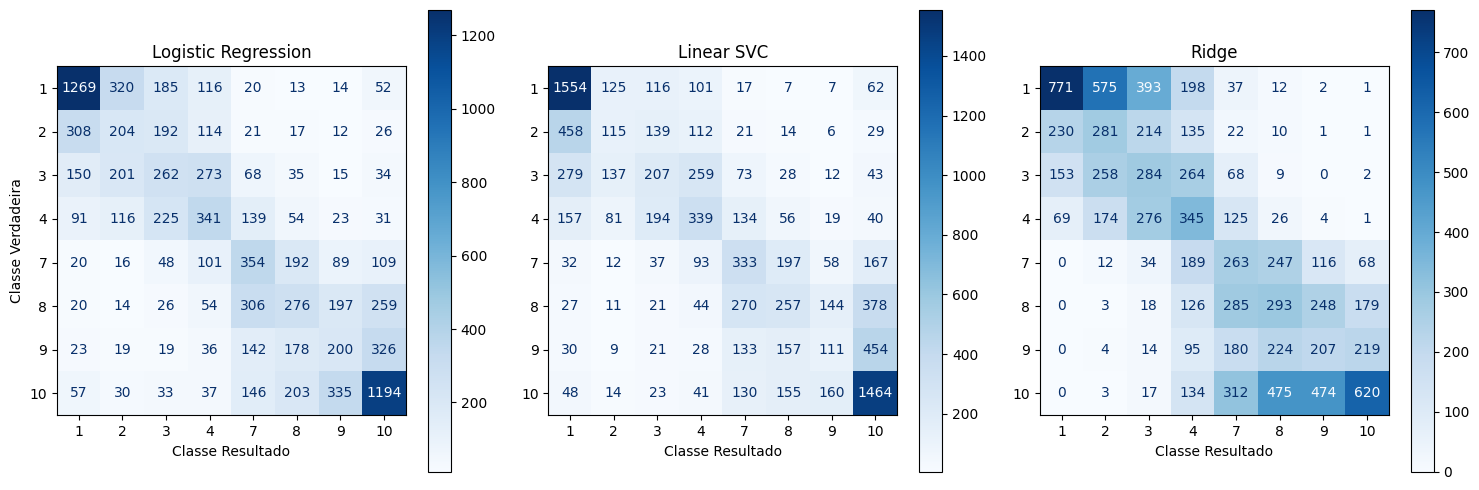

In [13]:
print("Report LogisticRegression")
print(lr_report)

print("Report LinearSVC")
print(lsvc_report)

print("Report Ridge")
print(ridge_report)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))  

# Logistic Regression
disp_lr = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=np.unique(yf))
disp_lr.plot(cmap='Blues', values_format='d', ax=axes[0])  
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Classe Resultado")  
axes[0].set_ylabel("Classe Verdadeira")  

# Linear SVC
disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=np.unique(yf))
disp_svm.plot(cmap='Blues', values_format='d', ax=axes[1])  
axes[1].set_title("Linear SVC")
axes[1].set_xlabel("Classe Resultado")  
axes[1].set_ylabel("") 

# Ridge
disp_ridge = ConfusionMatrixDisplay(confusion_matrix=cm_ridge, display_labels=np.unique(yf))
disp_ridge.plot(cmap='Blues', values_format='d', ax=axes[2])  
axes[2].set_title("Ridge")
axes[2].set_xlabel("Classe Resultado") 
axes[2].set_ylabel("")  

plt.tight_layout()
plt.show()

> Comentário:

Tal com já foi referido anteriormente, os relatórios de classificação indicam o desempenho dos modelos para cada classe e no conjunto geral de dados, permitindo uma análise detalhada.

**Logistic Regression:**
 * A precisão global (*accuracy*) foi de 41%.
 * Classes 1 e 10 tiveram os melhores desempenhos, com *f-scores* de 0.65 e 0.59, respetivamente. Isto sugere que o modelo tem maior facilidade em prever as pontuações extremas.
 * Classes intermediárias, como 2, 3, 8 e 9, tiveram um desempenho significativamente pior, com *f-scores* na faixa de 0.22 a 0.26.

**LinearSVC:**
 * Obteve uma precisão global de 44%, ligeiramente superior ao Logistic Regression.
 * Assim como o Logistic Regression, o desempenho foi melhor para as classes 1 (*f-scores* de 0.68) e 10 (*f-scores* de 0.63).
 * Classes intermediárias, como 2, 3, e 9, mantiveram um desempenho baixo (*f-scores* entre 0.15 e 0.25).

**Ridge:**
 * A precisão global foi de apenas 31%, bem inferior aos outros dois modelos.
 * A conversão dos valores contínuos para discretos resultou em um desempenho pior em prever classes extremas, especialmente 1 e 10, que apresentaram *f-scores* de 0.48 e 0.40, respetivamente.
 * O modelo mostrou-se mais disperso, com maior confusão entre as classes intermediárias.
 * Os piores resultados do regressor podem ser causados pelo passagem dos valores continuos para discretos do ``y_continuo = ridge.predict(Xf)``, pois os valores continuos são muito dispersos e encontraram-se dificuldades a obter melhores valores, em relação aos apresentados.

As matrizes de confusão ajudam a identificar os padrões de erro entre as previsões e os valores reais.

**Logistic Regression:**
 * Mostrou um bom número de acertos para as classes 1 e 10, com 1269 e 1194 amostras corretamente classificadas, respetivamente.
 * Classes intermediárias apresentaram confusões significativas, como 3, que foi frequentemente confundida com 4 e 2.
 * A confusão foi mais comum entre classes adjacentes, o que é esperado em um problema de classificação de criticas de cinema.

**LinearSVC:**
 * Melhorou o desempenho em classes extremas, com mais previsões corretas para 1 (1554) e 10 (1464).
 * As confusões em classes intermediárias, como 3 e 4, ainda são evidentes, mas ligeiramente menos pronunciadas do que no Logistic Regression.
 * O modelo apresenta uma distribuição de previsões mais centrada nas classes representadas, as classes que têm mais exemplos, 1 e 10 como têm mais dados, este classificador consegue acertar mais nestas classes (um dos fatores que faz aumentar o *score* deste classificador em comparação com o Logistic Regression).

**Ridge:**
 * Apresentou o maior grau de confusão entre as classes. Muitas previsões para 1 foram deslocadas para outras classes (como 2 e 3).
 * Classes intermediárias, como 3, 4, e 7, foram extremamente dispersas, indicando que o modelo não conseguiu capturar adequadamente as diferenças entre elas.
 * A matriz de confusão reflete o impacto negativo da conversão de valores contínuos em discretos.

Em resumo, a análise das matrizes de confusão evidencia que os modelos têm maior dificuldade em prever classes intermediárias, o que pode estar relacionado à distribuição dos dados ou à sobreposição nas características das pontuações adjacentes.

--------------------------------------

## *Clustering*

*Clustering* é uma técnica de aprendizado não supervisionado que organiza dados em grupos (ou *clusters*) com base na sua similaridade. A ideia central é que os itens dentro de um *cluster* sejam mais semelhantes entre si do que em relação a itens de outros *clusters*. No contexto de análise de texto, *clustering* pode ser usado para identificar temas ou tópicos comuns em conjuntos de dados não rotulados.

Neste projeto, foi realizada uma análise de *clustering* para identificar agrupamentos de críticas de filmes com características semelhantes, com base em representações numéricas (TF-IDF) das críticas. 

Inicialmente, repetiu-se o processo de transformação do texto com o TfidfVectorizer, desta vez com a utilização do parâmetro ``stopwords='english'``, pois o objetivo do *clustering* é agrupar as criticas sobre tópicos de filmes, logo não é necessário dar importância a *stopwords*.

Devido ao volume dos dados, foi criada uma amostra de 25000 críticas (metade do *dataset*) para o processo de ``TfidfVectorizer`` e *clustering*. Para lidar com a alta dimensionalidade dos dados TF-IDF, foi utilizada a técnica *Truncated Singular Value Decomposition* (``TruncatedSVD``) para reduzir os dados para 10 dimensões principais, preservando a maior parte da variabilidade.

O método hierárquico foi escolhido para realizar os agrupamentos. Ele organiza os dados em uma hierarquia de *clusters*, representada por um dendrograma. Esse dendrograma ilustra como os *clusters* são formados, mostrando as etapas em que os grupos de dados são combinados com base em sua proximidade, até que todos os dados estejam agrupados em um único conjunto.
A formação de *clusters* foi baseada em dois diferentes cortes no dendrograma, definidos pela distância vertical no gráfico, permitindo explorar diferentes agrupamentos dos dados:

* Corte com mais *clusters* (2.5): Este corte resulta em um maior número de *clusters*, o que permite identificar padrões mais detalhados e distintos entre críticas.

* Corte com menos *clusters* (7.5): Este corte, por sua vez, gera um menor número de *clusters* permitindo observar padrões mais generalizados, possibilitando a análise de características globais entre as críticas.

Estes valores foram escolhido através da visualização do dendrograma, onde apartir de vários testes, valores diferentes de ``n_clusters`` foram testados e consideraram-se estes os melhores.

Os resultados do *clustering* hierárquico foram refinados utilizando o algoritmo ``K-Means``. Este algoritmo é utilizado em *clustering* por dividir dados em *clusters* de maneira iterativa. O algoritmo k-médias baseia-se em representar dados através de n centroides, sendo que cada ponto pertence ao centroide mais próximo. O número de *clusters* foi ajustado para o mesmo número identificado pelo método hierárquico.

Para cada *cluster*, foi calculada a média dos valores TF-IDF associados às críticas pertencentes a ele. Em seguida, as palavras mais importantes (com maiores valores médios de TF-IDF) foram identificadas para descrever o conteúdo temático de cada agrupamento. Estas palavras são representativas das características mais frequentes de cada *cluster*.

In [14]:
num_samples = 25000
Xt_sample = X[:num_samples]

Xt_sample = clean_text(Xt_sample)
Xt_sample = [' '.join([stemFunc.stem(w) for w in x.split()]) for x in Xt_sample]

max_feature = len(Xt_sample) - 1000

tfidf = TfidfVectorizer(min_df=3, max_features=max_feature, token_pattern=tp, ngram_range=(1, 2), stop_words='english').fit(Xt_sample)
Xt_sample = tfidf.transform(Xt_sample)

# Redução das dimensões com TruncatedSVD (10 dimensões)
svd = TruncatedSVD(n_components=10, random_state=42)  # Reduz para 10 dimensões
Xt_reduced = svd.fit_transform(Xt_sample)

# Clustering hierárquico
linkage_matrix = linkage(Xt_reduced, method='ward')
n_cluster = 2.5

def numero_clusters(dist):
    """
    Método que realiza a formação de clusters com base em uma distância de corte e 
    calcula as palavras mais importantes de cada cluster.

    Args:
        - dist: Distância de corte utilizada para formar os clusters, 
        que define a separação entre os clusters no método hierárquico de agrupamento.

    Returns:
        - num_clusters: Número de clusters formados com base na distância de corte.
        - cluster_labels: Rótulos de cluster atribuídos a cada ponto de dados.
    """

    # Formar clusters com base na distância de corte
    clusters = fcluster(linkage_matrix, t=dist, criterion='distance')

    # Obter o número único de clusters formados
    num_clusters = len(np.unique(clusters))
    print(f"Número de clusters: {num_clusters}")

    kmeans = KMeans(n_clusters=num_clusters, random_state=42)
    cluster_labels = kmeans.fit_predict(Xt_sample)

    # Calcular os valores médios de TF-IDF para cada cluster
    tfidf_array = Xt_sample.toarray()
    cluster_tfidf_means = np.array([tfidf_array[cluster_labels == i].mean(axis=0) for i in range(num_clusters)])

    # Identificar as palavras mais importantes em cada cluster
    tokens = tfidf.get_feature_names_out()
    for i in range(num_clusters):
        top_words_idx = cluster_tfidf_means[i].argsort()[-10:][::-1]
        top_words = [tokens[j] for j in top_words_idx]
        print(f"Cluster {i}: Palavras mais importantes: {top_words}")

    return num_clusters, cluster_labels

num_clusters, cluster_labels = numero_clusters(n_cluster)

Número de clusters: 20
Cluster 0: Palavras mais importantes: ['wast', 'wast time', 'movi', 'time', 'don wast', 'don', 'money', 'film', 'watch', 'bad']
Cluster 1: Palavras mais importantes: ['movi', 'film', 'like', 'time', 'watch', 'just', 'onli', 'look', 'good', 'scene']
Cluster 2: Palavras mais importantes: ['stori', 'movi', 'film', 'good', 'veri', 'charact', 'love', 'like', 'true', 'life']
Cluster 3: Palavras mais importantes: ['game', 'play', 'movi', 'video game', 'graphic', 'level', 'contest', 'like', 'time', 'video']
Cluster 4: Palavras mais importantes: ['bad', 'movi', 'act', 'film', 'bad movi', 'good', 'like', 'just', 'watch', 'realli']
Cluster 5: Palavras mais importantes: ['film', 'like', 'veri', 'make', 'just', 'good', 'watch', 'charact', 'time', 'realli']
Cluster 6: Palavras mais importantes: ['movi', 'great', 'love', 'veri', 'time', 'good', 'watch', 'like', 'great movi', 'realli']
Cluster 7: Palavras mais importantes: ['book', 'read', 'read book', 'movi', 'novel', 'film', '

> Comentário:

O número escolhido de ``n_clusters = 2.5`` levou a separação dos dados em 20 *clusters*, o que resultou em uma separação mais detalhada e específica dos dados, permitindo identificar tópicos mais direcionados abordados nas críticas. Abaixo, os principais temas atribuídos a cada *cluster* com base nas palavras mais importantes identificadas:

 * **Cluster 0**: Críticas negativas sobre filmes considerados perda de tempo ou dinheiro. Termos como "wast time" e "bad" indicam uma clara insatisfação. <br>
   **Tema**: Perda de tempo e filmes de baixa qualidade.

 * **Cluster 1**: Comentários gerais sobre filmes e aspetos visuais ("look", "scene"). Palavras indicam opiniões mistas.<br>
   Tema: Aspetos gerais e visuais dos filmes.

 * **Cluster 2**: Críticas relacionadas a histórias envolventes e aspetos emocionais, com termos como "love", "true" e "life".<br>
   **Tema**: Histórias emocionantes e relacionáveis.

 * **Cluster 3**: Foco em jogos, gráficos e competições. Este *cluster* parece discutir adaptações de jogos ou filmes com temas de videojogos.<br>
   **Tema**: Filmes relacionados a videojogos.

 * **Cluster 4**: Críticas negativas, mas com foco em atuação ("act") e execução.<br>
   **Tema**: Filmes mal executados ou com má atuação.

 * **Cluster 5**: Comentários gerais e neutros sobre filmes.<br>
   **Tema**: Opiniões gerais sobre filmes.

 * **Cluster 6**: Críticas positivas ("great movi").<br>
   **Tema**: Criticas positivas sobre filmes.

 * **Cluster 7**: Críticas sobre adaptações de livros, como romances ("novel", "jane", "adapt", "read book").<br>
   **Tema**: Adaptações literárias.

 * **Cluster 8**: Foco em musicais e dança, com termos como "danc", "music", e "sing".<br>
   **Tema**: Musicais.

 * **Cluster 9**: Críticas gerais e misturadas sobre personagens, com tom neutro a ligeiramente negativo.<br>
   **Tema**: Criticas neutras/negativas sobre filmes e personagens.

 * **Cluster 10**: Discussão sobre *performances* e atuação, incluindo "perform", "role" e "actor".<br>
   **Tema**: Atuações e elencos.

 * **Cluster 11**: Foco em comédias, com palavras como "comedi", "funni" e "joke".<br>
   **Tema**: Comédias.

 * **Cluster 12**: Críticas relacionadas a histórias sombrias ou de suspense, como assassinatos e drama familiar ("murder", "kill", "father", "young").<br>
   **Tema**: Suspense e dramas familiares.

 * **Cluster 13**: Discussões sobre documentários ou histórias de vida real ("documentari", "life", "peopl").<br>
   **Tema**: Documentários e filmes baseados na realidade.

 * **Cluster 14**: Filmes de guerra, destacando temas históricos ("world war", "soldier", "american", "german").<br>
   **Tema**: Filmes de guerra.

 * **Cluster 15**: Filmes animados e obras da Disney, como "cartoon", "disney" e personagens clássicas ("cinderella").<br>
   **Tema**: Animações e filmes da Disney.

 * **Cluster 16**: Filmes de ficção científica com destaque para efeitos especiais ("special effect", "sci fi").<br>
   **Tema**: Ficção científica e efeitos especiais.

 * **Cluster 17**: Críticas relacionadas ao gênero de horror ("horror", "zombi", "gore").<br>
   **Tema**: Filmes de horror.

 * **Cluster 18**: Comentários gerais sobre filmes vistos anteriormente ("watch movie", "seen", "think").<br>
   **Tema**: Opiniões gerais de filmes.

 * **Cluster 19**: Críticas sobre séries de TV ("episod", "season", "tv").<br>
   **Tema**: Séries de TV

Esta separação em 20 *clusters* foi útil para encontrar grupos de críticas que abordam diretamente gêneros específicos, características técnicas (como efeitos especiais e atuações), e até mesmo comentários sobre séries de TV.

## Dendrograma - Corte com mais *clusters* (2.5)

Tal como já foi referido anteriormente, dendrogramas ilustram como os *clusters* são formados, mostrando as etapas em que os grupos de dados são combinados com base na sua proximidade, até que todos os dados estejam agrupados em um único conjunto.

O dendrograma foi criado com o método ``linkage``, utilizando o critério de ligação ``Ward``, que minimiza a variância dentro de cada *cluster*.
Para simplificar a visualização e evitar sobrecarga de informações, apenas os primeiros 5 níveis do dendrograma foram exibidos (``truncate_mode='level', p=5``).

Para destacar o ponto de corte no dendrograma (definido pelo parâmetro ``n_cluster``), foi adicionada uma linha horizontal na altura correspondente, que indica a separação entre os grupos. Esta linha é essencial para demonstrar visualmente como os *clusters* foram formados com base em diferentes distâncias de corte.

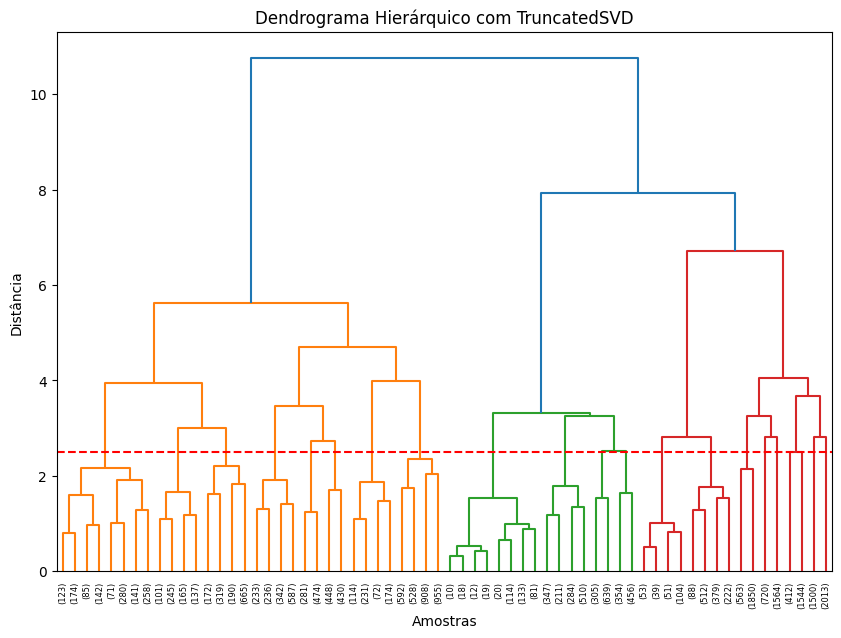

In [15]:
# Plot do dendrograma
plt.figure(figsize=(10, 7))
dendrogram(linkage_matrix, truncate_mode='level', p=5)
plt.title("Dendrograma Hierárquico com TruncatedSVD")
plt.xlabel("Amostras")
plt.ylabel("Distância")
plt.axhline(y=n_cluster, color='r', linestyle='--') 
plt.show()

## Corte com menos *clusters* (7.5)

Repetiu-se os passos anteriores, mas agora escolheu-se o valor de ``n_cluster = 7.5`` como ponto de corte no dendrograma. Este corte resultou em uma divisão dos dados em 3 *clusters*, o objetivo desta divisão é obter *clusters* mais genéricos, permitindo assim analisar caracteristicas mais globais entre as críticas.

Realizou-se outra vez a visualização do dendrograma, onde se colocou uma linha horizontal na altura correspondente ao valor de ``n_cluster``, que indica a separação entre os grupos.

Além disso, foi criado um gráfico 2D para visualizar a distribuição dos pontos de dados nos seus respectivos *clusters*. Cada ponto foi colorido conforme o *cluster* ao qual pertence, facilitando a identificação dos agrupamentos. O gráfico revelou uma separação clara entre os 3 *clusters* resultantes, cada um representando um conjunto distinto de características compartilhadas pelas críticas.

Este passo não foi realizado para o corte com ``n_cluster = 2.5``, pois, devido ao número elevado de *clusters* e à proximidade entre os dados, a visualização dos agrupamentos tornou-se pouco legível. A divisão com 7.5 oferece uma visão mais clara das estruturas gerais entre as críticas.

Número de clusters: 3
Cluster 0: Palavras mais importantes: ['movi', 'like', 'watch', 'bad', 'just', 'good', 'realli', 'time', 'make', 'don']
Cluster 1: Palavras mais importantes: ['film', 'like', 'veri', 'make', 'just', 'movi', 'charact', 'good', 'time', 'stori']
Cluster 2: Palavras mais importantes: ['movi', 'film', 'like', 'stori', 'time', 'charact', 'just', 'veri', 'good', 'love']


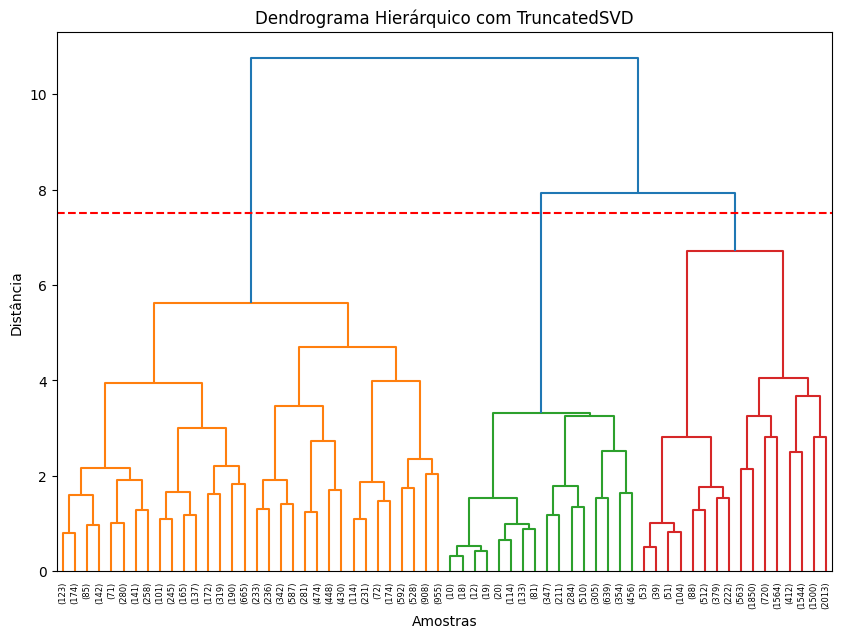

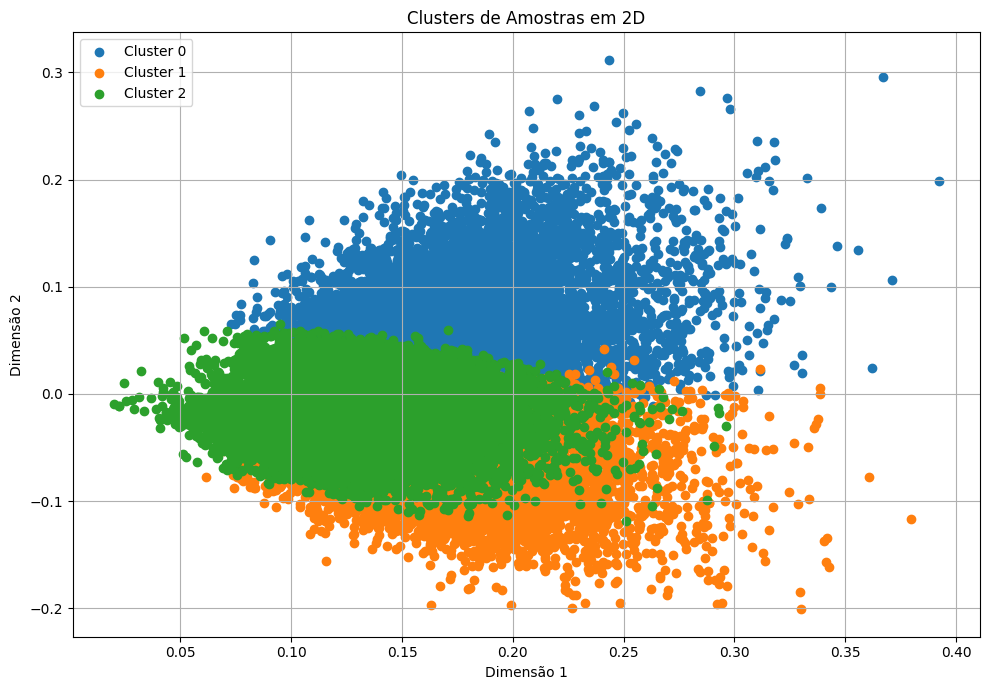

In [16]:
n_cluster = 7.5
num_clusters, cluster_labels = numero_clusters(n_cluster)
plt.figure(figsize=(10, 7))
dendrogram(linkage_matrix, truncate_mode='level', p=5)
plt.title("Dendrograma Hierárquico com TruncatedSVD")
plt.xlabel("Amostras")
plt.ylabel("Distância")
plt.axhline(y=n_cluster, color='r', linestyle='--') 
plt.show()

plt.figure(figsize=(10, 7))

for i in range(num_clusters):
    plt.scatter(Xt_reduced[cluster_labels == i, 0], 
                Xt_reduced[cluster_labels == i, 1], 
                label=f"Cluster {i}")
plt.title("Clusters de Amostras em 2D")
plt.xlabel("Dimensão 1")
plt.ylabel("Dimensão 2")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

> Comentário:

O número escolhido de ``n_clusters = 7.5`` levou a separação dos dados em 3 *clusters*, o que resultou em uma separação mais genérica dos dados. Abaixo, os principais temas atribuídos a cada *cluster* com base nas palavras mais importantes identificadas:

 * **Cluster 0**: Este *cluster* parece agrupar críticas focadas em perceções gerais sobre filmes, com um tom misto entre positivo e negativo. Termos como "bad" e "good" indicam opiniões polarizadas.<br>
   **Tema**: Impressões gerais sobre filmes.

 * **Cluster 1**: Aqui, as críticas tem um tom mais descritivo, onde enfatizam elementos como personagens ("charact") e histórias ("stori").<br>
   **Tema**: Análise de histórias e personagens.

 * **Cluster 2**: Este *cluster* abrange críticas emocionais, com destaque para "love", "stori" e "charact". Ele representa uma visão mais positiva ou apreciativa.<br>
   **Tema**: Criticas emocionantes.

## Comparação entre os dois cenários de *clustering*

**Clusters = 20:** 
 * Permitiu a identificação de gêneros específicos (animação, horror, comédia) e elementos técnicos (efeitos especiais, atuação).
 * Útil para análises detalhadas e identificação de padrões em tópicos específicos.

**Clusters = 3:** 
 * Resultou em agrupamentos mais genéricos.
 * Simplifica a análise, agrupando críticas com base em emoções e percepções gerais.
 * Útil para uma visão geral inicial, mas perde detalhes sobre tópicos específicos.

## Conclusão

Neste trabalho, explorou-se um conjunto de dados de críticas de filmes do IMDb, implementando técnicas de classificação e regressão para análise e classificação das notas atribuídas às críticas. Para as tarefas supervisionadas, foram utilizados modelos como Regressão Logística, LinearSVC e Ridge (dois classificadores e um regressor respetivamente).
Também se realizou agrupamento de críticas de forma não supervisionada através de *clustering* hierárquico e K-Means.

Os resultados obtidos destacaram a dificuldade dos classificadores em lidar com classes intermediárias, enquanto apresentaram um bom desempenho para classes extremas, como 1 e 10. Entre os modelos testados, o LinearSVC apresentou o melhor desempenho geral, com uma precisão ligeiramente superior à Regressão Logística. Por outro lado, o Ridge, apesar de sua capacidade preditiva em valores contínuos, teve um desempenho inferior após a conversão para valores discretos.

A análise de *clustering* permitiu identificar agrupamentos significativos, como gêneros específicos e elementos técnicos, sendo particularmente útil para compreender padrões temáticos em grandes volumes de dados textuais. Além disso, a comparação entre diferentes valores de *clusters* (20 e 3) evidenciou a versatilidade do método em fornecer tanto uma visão detalhada quanto análises mais gerais.

## Bibliografia 

### Consulta:

Marques, Gonçalo. (2024 - 2025). Aprendizagem Automática - Moodle

LinearSVC. (2024). Scikit-Learn. https://scikit-learn.org/1.5/modules/generated/sklearn.svm.LinearSVC.html

‌LogisticRegression. (2024). Scikit-Learn. https://scikit-learn.org/1.5/modules/generated/sklearn.linear_model.LogisticRegression.html

NLTK :: nltk.stem.SnowballStemmer. (2023). Nltk.org. https://www.nltk.org/api/nltk.stem.SnowballStemmer.html?highlight=stopwords

TfidfVectorizer. (2024). Scikit-Learn. https://scikit-learn.org/1.5/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html

‌Ridge. (2024). Scikit-Learn. https://scikit-learn.org/1.5/modules/generated/sklearn.linear_model.Ridge.html

‌KMeans. (2024). Scikit-Learn. https://scikit-learn.org/1.5/modules/generated/sklearn.cluster.KMeans.html